In [1]:
import numpy.random as rnd
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import scipy as sp
from scipy.stats import norm
import pandas_datareader as pd_data
from pandas_datareader import data as pdr
from datetime import datetime
from scipy.interpolate import interp1d 
# from scipy import arange, array, exp
from scipy.optimize import brentq
from scipy.interpolate import griddata
import datacleaning as dc
from opengreeks import black76
import os
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import display, clear_output

In [2]:
def Black76_OptionPrice(St,tau,F,K,dir,sigma):
    """
    St: current asset price (at time t)
    tau: time to expiry of the option
    F: forward price
    K: strike
    sigma: volatility
    ***all of the above can be both vectors and scalars***
    returns CALL PRICE(s) using the Black-76 formula
    """
    efact = F/St
    #delta of the option
    d1 = (np.log(F/K)+tau*0.5*sigma*sigma)/(sigma*np.sqrt(tau))
    d2 = d1-sigma*np.sqrt(tau)
    price = efact*(F*norm.cdf(d1)-K*norm.cdf(d2))
    if dir == 'CE':
        price = efact*(F*norm.cdf(d1)-K*norm.cdf(d2))
    elif dir == 'PE': 
        price = efact*(-F*norm.cdf(-d1)+K*norm.cdf(-d2))
    return price

def BS_OptionPrice(St,tau,r,K,dir,sigma):
    """
    St: current asset price (at time t)
    tau: time to expiry of the option
    r: risk-free interest rate
    K: strike
    sigma: volatility
    ***all of the above can be both vectors and scalars***
    returns CALL PRICE(s) using the Black-Scholes formula
    """
    #delta
    d1 = (np.log(St/K)+tau*(r+0.5*sigma*sigma))/(sigma*np.sqrt(tau))
    d2 = d1-sigma*np.sqrt(tau)
    if dir == 'CE':
        price = St*norm.cdf(d1)-K*norm.cdf(d2)*np.exp(-r*tau)
    elif dir == 'PE': 
        price = K*norm.cdf(-d2)*np.exp(-r*tau) - St*norm.cdf(-d1)

    return price

#Converting from K,T to m,tau
def K_T_to_mu_tau(K,T,St,t):
    return K/St,T-t
def mu_tau_to_K_T(mu,tau,St,t):
    return mu*St,tau+t

In [3]:
# %load_ext autoreload
# %autoreload 2

In [4]:
df_niftyoptions= pd.read_csv('data/niftyoptions_df.csv')
df_niftyspot = pd.read_csv('data/nifty_close.csv')

niftyoptions_df, niftyspot_df, spot, observation_dates = dc.optiondata_transform(df_niftyoptions, df_niftyspot)
datapath = 'data/datapath.csv'

def create_data(
    observation_dates,
    niftyoptions_df,
    niftyspot_df,
    m_grid=None,
    tau_days=None,
    datapath=datapath
):
    """
    datapath: Option-level data with calculated implied volatility.
    Parameters
    ----------
    observation_dates : iterable Trading observation_dates to process.
    niftyoptions_df : pd.DataFrame Preprocessed NIFTY option data.
    niftyspot_df : pd.DataFrame NIFTY spot data.
    m_grid : array-like Fixed moneyness grid.
    tau_days : array-like Fixed maturity grid in calendar days.
    datapath : str Output path for option-level data.
    surfacepath : str Output path for flattened surfaces.
    """

    if m_grid is None:
        m_grid = np.linspace(0.6, 1.4, 10)

    if tau_days is None:
        tau_days = np.array([7, 14, 30, 60,90, 180, 270, 365])

    tau_grid = np.asarray(tau_days) / 365.0

    data_list = []
    surface_list = []

    for date in observation_dates:

        subset_df, r1 = dc.data_day(date,niftyoptions_df,niftyspot_df)
        call_df = subset_df[subset_df["option_type"] == "CE"].copy()
        put_df = subset_df[subset_df["option_type"] == "PE"].copy()

        def solve_iv(row):
            F = row["spot"]
            St = row['spot']
            tau = row["ttm"]
            K = row["strike"]
            market_price = row["mid_price"]
            dir = row["option_type"]
            r = row['r']

            if (pd.isna(St) or pd.isna(tau) or pd.isna(K) or pd.isna(market_price)):
                return np.nan

            if St <= 0 or tau <= 0 or market_price <= 0:
                return np.nan

            def objective(sigma):
                model_price = Black76_OptionPrice(St,tau,F,K,dir,sigma)
                return model_price - market_price

            try:
                return brentq(objective, 1e-6, 5.0)
            except ValueError:
                return np.nan

        call_df["iv"] = call_df.apply( solve_iv, axis=1)
        call_df = call_df[call_df["iv"].notna()].copy()
        call_df = call_df[(call_df["iv"] > 0) & (call_df["iv"] < 5)].copy()
        data_list.append(call_df)

        put_df["iv"] = put_df.apply( solve_iv, axis=1)
        put_df = put_df[put_df["iv"].notna()].copy()
        put_df = put_df[(put_df["iv"] > 0) & (put_df["iv"] < 5)].copy()
        data_list.append(put_df)

    if len(data_list) > 0:
        data_output = pd.concat(data_list,ignore_index=True)
    else:
        data_output = pd.DataFrame()

    data_output.to_csv(datapath,index=False)
    print(f"datapath saved to: {datapath}")
    print(f"datapath shape: {data_output.shape}")

    return data_output

In [5]:
# subset_df, r = dc.data_day(observation_dates[0],niftyoptions_df,niftyspot_df)

In [6]:
# if os.path.exists('data/nifty_df.parquet') and False:
if os.path.exists('data/nifty_df.parquet'):
    nifty_df = pd.read_parquet('data/nifty_df.parquet')    
else:
    nifty_df = create_data(observation_dates,niftyoptions_df,niftyspot_df)
    nifty_df.to_parquet('data/nifty_df.parquet', index = False)

In [7]:
greek_functions = {
    "delta": black76.delta,
    "gamma": black76.gamma,
    "vega": black76.vega,
    "theta": black76.theta,
    "rho": black76.rho,
    "vanna": black76.vanna,
    "charm": black76.charm,
    "vomma": black76.vomma,
    "speed": black76.speed,
    "zomma": black76.zomma,
    "color": black76.color,
    "veta": black76.veta,
    "ultima": black76.ultima,
    "dual_delta": black76.dual_delta,
    "dual_gamma": black76.dual_gamma,
}


def calculate_greeks(row):
    F = float(row["spot"])
    K = float(row["strike"])
    t = float(row["ttm"])
    RATE = float(row["r"])
    price = float(row["close"])

    flag = {"CE": "c", "PE": "p"}.get(str(row["option_type"]).upper())

    result = {
        "implied_volatility": np.nan,
        "model_price": np.nan,
        "greek_error": None,
    }
    
    if flag is None or not all(
        np.isfinite(x) for x in [F, K, t, price]
    ) or F <= 0 or K <= 0 or t <= 0 or price <= 0:
        result["greek_error"] = "Invalid input"
        return pd.Series(result)

    try:
        iv = black76.implied_volatility(price, F, K, RATE, t, flag)
        if not np.isfinite(iv) or iv <= 0:
            raise ValueError("Invalid implied volatility")

        result["implied_volatility"] = iv
        result["model_price"] = black76.black(flag, F, K, t, RATE, iv)

        for name, func in greek_functions.items():
            result[name] = func(flag, F, K, t, RATE, iv)

    except Exception as exc:
        result["greek_error"] = str(exc)
    return pd.Series(result)

In [8]:
# if os.path.exists('data/df_with_greeks.parquet') and False:
if os.path.exists('data/df_with_greeks.parquet'):
    df_with_greeks = pd.read_parquet('data/df_with_greeks.parquet')    
else:
    greek_columns = nifty_df.apply(calculate_greeks, axis=1)

    df_with_greeks = pd.concat(
        [nifty_df.reset_index(drop=True),
        greek_columns.reset_index(drop=True)],
        axis=1,
    )
    df_with_greeks.to_parquet('data/df_with_greeks.parquet', index = False)

In [9]:
# nifty_df[(nifty_df['date'] == '2025-01-01')&(nifty_df['days_to_exp']==15)& (nifty_df['option_type'] == 'CE')].sort_values('strike')

In [10]:
# df_with_greeks
# df_with_greeks[(df_with_greeks['date'] == '2025-01-01')&(df_with_greeks['days_to_exp']==15)& (df_with_greeks['option_type'] == 'CE')][list(nifty_df.columns) + ['delta']].sort_values('strike')


In [11]:
dts = df_with_greeks['date'].unique()
numeric_cols = ["strike", "close", "ttm", "days_to_exp","delta", "gamma", "vega", "theta", "rho","vanna",
                 "charm", "vomma", "speed", "zomma","color", "veta", "ultima", "dual_delta", "dual_gamma"]
day_to_exp = np.sort(df_with_greeks['days_to_exp'].unique())

In [13]:
dts = df_with_greeks['date'].unique()
sensi_list = ["delta", "gamma", "vega", "theta", "rho","vanna","charm", "vomma", "speed", "zomma","color", "veta", "ultima", "dual_delta", "dual_gamma"]
sensi = 'delta'

# df = df_with_greeks[(df_with_greeks['date'] == dts[0])] 
# plt.figure(figsize=(10, 6))

# # for dt in df['days_to_exp'].unique():
# for dt in [1]:
#     for opt in ['CE', 'PE']:
#         temp = df[(df['option_type'] == opt) & (df['days_to_exp'] == dt)].sort_values('strike')

#         plt.plot(temp['strike'],temp[sensi],marker='.',label=opt)

# plt.axhline(0, linestyle='--', linewidth=0.8)
# plt.xlabel('Strike')
# plt.ylabel('Delta')
# plt.title(f'Option Delta vs Strike — {dts[0]}')
# # plt.legend()
# plt.grid(True)
# plt.show()


In [14]:
date_dd = widgets.Dropdown(
    options=sorted(df_with_greeks['date'].unique()),
    description='Date:'
)
sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
# ttm_dd2 = widgets.Dropdown(description='Days to maturity:')

opt_dd = widgets.Dropdown(options = [['CE'],['PE'],['CE', 'PE']], value= ['CE', 'PE'], description='Days to maturity:')

def update_ttm(*args):
    dates = df_with_greeks[df_with_greeks['date'] == date_dd.value]
    ttm_dd.options = sorted(dates['days_to_exp'].unique())
    if len(ttm_dd.options):
        ttm_dd.value = ttm_dd.options[0]

    # ttm_dd2.options = sorted(dates['days_to_exp'].unique())
    # ttm_dd.value = ttm_dd.options[1]

date_dd.observe(update_ttm, names='value')
update_ttm()

def plot_greek(date, sensi, dtm, instr):#, dtm2 = None):
    df = df_with_greeks[df_with_greeks['date'] == date]

    plt.figure(figsize=(10, 6))
    for opt in instr:
        temp = df[(df['option_type'] == opt) & (df['days_to_exp'] == dtm)].sort_values('strike')
        plt.plot(temp['strike'], temp[sensi], marker='.', label=opt)

        # if dtm2 != None:
        #     temp2 = df[(df['option_type'] == opt) & (df['days_to_exp'] == dtm2)].sort_values('strike')
        #     plt.plot(temp2['strike'], temp2[sensi], marker='.', label=opt)


    plt.axhline(0, linestyle='--', linewidth=0.8)
    plt.xlabel('Strike')
    plt.ylabel(sensi)
    plt.title(f'{sensi.capitalize()} vs Strike — {date}, DTM={dtm}')#,  DTM2 ={dtm2}')
    plt.legend()
    plt.grid(True)
    plt.show()
    # plt.close()

widgets.interactive(plot_greek, date=date_dd, sensi=sensi_dd, dtm=ttm_dd, instr = opt_dd)#, dtm2 = ttm_dd2)

interactive(children=(Dropdown(description='Date:', options=('2025-01-01', '2025-01-02', '2025-01-03', '2025-0…

In [18]:
def plot_surface(date, sensi):
    df = df_with_greeks[df_with_greeks['date'] == date]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    for opt in ['CE', 'PE']:
        temp = df[df['option_type'] == opt]

        surf = temp.pivot_table(
            index='days_to_exp',
            columns='strike',
            values=sensi,
            aggfunc='mean'
        ).sort_index().sort_index(axis=1)

        X, Y = np.meshgrid(surf.columns, surf.index)
        Z = surf.to_numpy(dtype=float)

        ax.plot_surface(X, Y, Z, alpha=0.7)

    ax.set_xlabel('Strike')
    ax.set_ylabel('Days to Maturity')
    ax.set_zlabel(sensi)
    ax.set_title(f'{sensi.capitalize()} Surface — {date}')

    plt.show()

In [ ]:
date_dd = widgets.Dropdown(
    options=sorted(df_with_greeks['date'].unique()),
    description='Date:'
)
sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
opt_dd = widgets.Dropdown(options = [['CE'],['PE'],['CE', 'PE']], value= ['CE', 'PE'], description='Days to maturity:')

widgets.interactive(plot_greek, date=date_dd, sensi=sensi_dd, dtm=ttm_dd, instr = opt_dd)

surface_btn = widgets.Button(description='Plot Surface')
out = widgets.Output()

def on_surface_click(b):
    with out:
        out.clear_output(wait=True)
        plot_surface(date_dd.value, sensi_dd.value)

surface_btn.on_click(on_surface_click)
display(surface_btn, out)

Button(description='Plot Surface', style=ButtonStyle())

Output()

In [ ]:
def plot_surface(date, sensi, instr):
    df = df_with_greeks[df_with_greeks['date'] == date]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    for opt in instr:
        temp = df[df['option_type'] == opt]

        surf = temp.pivot_table(
            index='days_to_exp',
            columns='strike',
            values=sensi,
            aggfunc='mean'
        ).sort_index().sort_index(axis=1)

        X, Y = np.meshgrid(surf.columns, surf.index)
        Z = surf.to_numpy(dtype=float)

        ax.plot_surface(X, Y, Z, alpha=0.7)

    ax.set_xlabel('Strike')
    ax.set_ylabel('Days to Maturity')
    ax.set_zlabel(sensi)
    ax.set_title(f'{sensi.capitalize()} Surface — {date}')
    plt.show()


surface_btn = widgets.Button(description='Plot Surface')
out = widgets.Output()

def on_surface_click(b):
    with out:
        out.clear_output(wait=True)
        plot_surface(date_dd.value, sensi_dd.value, opt_dd.value)

surface_btn.on_click(on_surface_click)
display(widgets.HBox([date_dd, sensi_dd, opt_dd]), surface_btn, out)
# display(surface_btn, out)

Button(description='Plot Surface', style=ButtonStyle())

Output()

### Extend to work with the synthetic series of sensitivities

In [23]:
def generate_synthetic_greeks(df_with_greeks, dt = '2025-01-01'):

    df_use = df_with_greeks[df_with_greeks['date'] == dt]
    S_range= [int(df_use['spot'].mean())] # Select the S from the actuals
    K_range=np.arange((S_range[0] - 6000),( S_range[0] +6000), 300) # Select K which are upper and lower for a given date selected
    # sigma_range=np.arange(0.08, 0.201, 0.02)
    # Give a 0 sigma to create the df, then change it in vol
    sigma_range = [0]
    r_ = df_use['r'].mean()
    r_range=np.array([r_-.01,r_,r_+.01]) # select from the table the actual and 1% on both side
    # T_range=np.array([1/365, 7/365, 14/365, 30/365, 60/365]) # all the days to maturity from the table
    T_range=np.array(np.sort(df_use['days_to_exp'].unique())/365) # all the days to maturity from the table
    option_types=('CE', 'PE')
    q=0.0

    df = pd.MultiIndex.from_product(
        [S_range, K_range, r_range, T_range, option_types],
        names=['spot', 'strike', 'r',
                'ttm', 'option_type']
    ).to_frame(index=False)

    S = df['spot'].to_numpy(dtype=float)
    K = df['strike'].to_numpy(dtype=float)
    # vol = df['implied_volatility'].to_numpy(dtype=float)
    r = df['r'].to_numpy(dtype=float)
    T = df['ttm'].to_numpy(dtype=float)
    is_call = df['option_type'].eq('CE').to_numpy()

    # Prepare actual implied volatility data
    iv_data = (
        df_use[['strike', 'option_type', 'days_to_exp', 'implied_volatility']]
        .dropna(subset=['strike', 'implied_volatility'])
        .copy()
    )

    iv_data['ttm'] = iv_data['days_to_exp'] / 365

    # Match nearest strike within the same option type and expiry
    df = df.sort_values('strike')
    iv_data = iv_data.sort_values('strike')
    iv_data['strike'] = iv_data['strike'].astype('int')

    df = pd.merge_asof(
        df,
        iv_data,
        on='strike',
        by=['option_type', 'ttm'],
        direction='nearest',
        tolerance=None
    )

    vol = df['implied_volatility'].to_numpy(dtype=float)


    sqrtT = np.sqrt(T)
    d1 = (np.log(S/K) + (r - q + 0.5*vol**2)*T) / (vol*sqrtT)
    d2 = d1 - vol*sqrtT
    pdf = norm.pdf(d1)
    disc_q = np.exp(-q*T)
    disc_r = np.exp(-r*T)

    # Price and standard analytical Greeks
    call = disc_q*S*norm.cdf(d1) - disc_r*K*norm.cdf(d2)
    put = disc_r*K*norm.cdf(-d2) - disc_q*S*norm.cdf(-d1)

    df['model_price'] = np.where(is_call, call, put)
    df['delta'] = disc_q * np.where(is_call, norm.cdf(d1), norm.cdf(d1) - 1)
    df['gamma'] = disc_q * pdf / (S*vol*sqrtT)
    df['vega'] = S*disc_q*pdf*sqrtT /100

    df['theta'] = (
        -S*disc_q*pdf*vol/(2*sqrtT)
        - np.where(
            is_call,
            r*K*disc_r*norm.cdf(d2),
            -r*K*disc_r*norm.cdf(-d2)
        )
        + np.where(
            is_call,
            q*S*disc_q*norm.cdf(d1),
            -q*S*disc_q*norm.cdf(-d1)
        )
    ) / 365.0  # calendar-day theta

    df['rho'] = (
        np.where(
            is_call, K*T*disc_r*norm.cdf(d2),
            -K*T*disc_r*norm.cdf(-d2)
        ) / 100.0
    )  

    def price(s, v, t):
        s = np.maximum(s, 1e-8)
        v = np.maximum(v, 1e-8)
        t = np.maximum(t, 1e-10)
        d_1 = (np.log(s/K) + (r-q+0.5*v**2)*t)/(v*np.sqrt(t))
        d_2 = d_1 - v*np.sqrt(t)
        c = disc_q*s*norm.cdf(d_1) - disc_r*K*norm.cdf(d_2)
        p = disc_r*K*norm.cdf(-d_2) - disc_q*s*norm.cdf(-d_1)
        return np.where(is_call, c, p)

    hs = np.maximum(S*1e-4, 0.01)
    hv = 1e-4
    ht = np.minimum(T*1e-3, 1e-5)

    p0 = price(S, vol, T)
    psu, psd = price(S+hs, vol, T), price(S-hs, vol, T)
    pvu, pvd = price(S, vol+hv, T), price(S, vol-hv, T)
    ptu, ptd = price(S, vol, T+ht), price(S, vol, T-ht)

    # Cross / higher derivatives
    df['vanna'] = (
        price(S+hs, vol+hv, T) - price(S+hs, vol-hv, T)
        - price(S-hs, vol+hv, T) + price(S-hs, vol-hv, T)
    ) / (4*hs*hv)

    df['vomma'] = (pvu - 2*p0 + pvd) / hv**2
    df['speed'] = (psu - 2*p0 + psd) / hs**2
    df['zomma'] = (
        (price(S+hs, vol, T) - 2*p0 + price(S-hs, vol, T))
        / hs**2
    )
    # Zomma = derivative of Gamma with respect to volatility
    gamma_up = np.exp(-q*T)*norm.pdf(
        (np.log(S/K)+(r-q+0.5*(vol+hv)**2)*T)
        / ((vol+hv)*sqrtT)
    )/(S*(vol+hv)*sqrtT)
    gamma_dn = np.exp(-q*T)*norm.pdf(
        (np.log(S/K)+(r-q+0.5*(vol-hv)**2)*T)
        / ((vol-hv)*sqrtT)
    )/(S*(vol-hv)*sqrtT)
    df['zomma'] = (gamma_up - gamma_dn)/(2*hv)

    df['moneyness'] = S/K
    df['days_to_exp'] = T*365

    return df

### Generate the plot comparing synthetic to actuals

In [24]:
# dt = '2025-01-01'

# df_use = df_with_greeks[df_with_greeks['date'] == dt]
# S_range= [int(df_use['spot'].mean())] # Select the S from the actuals
# K_range=np.arange((S_range[0] - 6000),( S_range[0] +6000), 300) # Select K which are upper and lower for a given date selected
# # sigma_range=np.arange(0.08, 0.201, 0.02)
# # Give a 0 sigma to create the df, then change it in vol
# sigma_range = [0]
# r_ = df_use['r'].mean()
# r_range=np.array([r_-.01,r_,r_+.01]) # select from the table the actual and 1% on both side
# # T_range=np.array([1/365, 7/365, 14/365, 30/365, 60/365]) # all the days to maturity from the table
# T_range=np.array(np.sort(df_use['days_to_exp'].unique())/365) # all the days to maturity from the table
# option_types=('CE', 'PE')
# q=0.0

# df = pd.MultiIndex.from_product(
#     [S_range, K_range, r_range, T_range, option_types],
#     names=['spot', 'strike', 'r',
#             'ttm', 'option_type']
# ).to_frame(index=False)

# S = df['spot'].to_numpy(dtype=float)
# K = df['strike'].to_numpy(dtype=float)
# # vol = df['implied_volatility'].to_numpy(dtype=float)
# r = df['r'].to_numpy(dtype=float)
# T = df['ttm'].to_numpy(dtype=float)
# is_call = df['option_type'].eq('CE').to_numpy()

# # Prepare actual implied volatility data
# iv_data = (
#     df_use[['strike', 'option_type', 'days_to_exp', 'implied_volatility']]
#     .dropna(subset=['strike', 'implied_volatility'])
#     .copy()
# )

# iv_data['ttm'] = iv_data['days_to_exp'] / 365

# # Match nearest strike within the same option type and expiry
# df = df.sort_values('strike')
# iv_data = iv_data.sort_values('strike')
# iv_data['strike'] = iv_data['strike'].astype('int')

# df = pd.merge_asof(
#     df,
#     iv_data,
#     on='strike',
#     by=['option_type', 'ttm'],
#     direction='nearest',
#     tolerance=None
# )

# vol = df['implied_volatility'].to_numpy(dtype=float)

# sqrtT = np.sqrt(T)
# d1 = (np.log(S/K) + (r - q + 0.5*vol**2)*T) / (vol*sqrtT)
# d2 = d1 - vol*sqrtT
# pdf = norm.pdf(d1)
# disc_q = np.exp(-q*T)
# disc_r = np.exp(-r*T)

# # Price and standard analytical Greeks
# call = disc_q*S*norm.cdf(d1) - disc_r*K*norm.cdf(d2)
# put = disc_r*K*norm.cdf(-d2) - disc_q*S*norm.cdf(-d1)

# df['model_price'] = np.where(is_call, call, put)
# df['delta'] = disc_q * np.where(is_call, norm.cdf(d1), norm.cdf(d1) - 1)
# df['gamma'] = disc_q * pdf / (S*vol*sqrtT)
# df['vega'] = S*disc_q*pdf*sqrtT

# df['theta'] = (
#     -S*disc_q*pdf*vol/(2*sqrtT)
#     - np.where(
#         is_call,
#         r*K*disc_r*norm.cdf(d2),
#         -r*K*disc_r*norm.cdf(-d2)
#     )
#     + np.where(
#         is_call,
#         q*S*disc_q*norm.cdf(d1),
#         -q*S*disc_q*norm.cdf(-d1)
#     )
# ) / 365.0  # calendar-day theta

# df['rho'] = (
#     np.where(
#         is_call, K*T*disc_r*norm.cdf(d2),
#         -K*T*disc_r*norm.cdf(-d2)
#     ) / 100.0
# )  

# def price(s, v, t):
#     s = np.maximum(s, 1e-8)
#     v = np.maximum(v, 1e-8)
#     t = np.maximum(t, 1e-10)
#     d_1 = (np.log(s/K) + (r-q+0.5*v**2)*t)/(v*np.sqrt(t))
#     d_2 = d_1 - v*np.sqrt(t)
#     c = disc_q*s*norm.cdf(d_1) - disc_r*K*norm.cdf(d_2)
#     p = disc_r*K*norm.cdf(-d_2) - disc_q*s*norm.cdf(-d_1)
#     return np.where(is_call, c, p)

# hs = np.maximum(S*1e-4, 0.01)
# hv = 1e-4
# ht = np.minimum(T*1e-3, 1e-5)

# p0 = price(S, vol, T)
# psu, psd = price(S+hs, vol, T), price(S-hs, vol, T)
# pvu, pvd = price(S, vol+hv, T), price(S, vol-hv, T)
# ptu, ptd = price(S, vol, T+ht), price(S, vol, T-ht)

# # Cross / higher derivatives
# df['vanna'] = (
#     price(S+hs, vol+hv, T) - price(S+hs, vol-hv, T)
#     - price(S-hs, vol+hv, T) + price(S-hs, vol-hv, T)
# ) / (4*hs*hv)

# df['vomma'] = (pvu - 2*p0 + pvd) / hv**2
# df['speed'] = (psu - 2*p0 + psd) / hs**2
# df['zomma'] = (
#     (price(S+hs, vol, T) - 2*p0 + price(S-hs, vol, T))
#     / hs**2
# )
# # Zomma = derivative of Gamma with respect to volatility
# gamma_up = np.exp(-q*T)*norm.pdf(
#     (np.log(S/K)+(r-q+0.5*(vol+hv)**2)*T)
#     / ((vol+hv)*sqrtT)
# )/(S*(vol+hv)*sqrtT)
# gamma_dn = np.exp(-q*T)*norm.pdf(
#     (np.log(S/K)+(r-q+0.5*(vol-hv)**2)*T)
#     / ((vol-hv)*sqrtT)
# )/(S*(vol-hv)*sqrtT)
# df['zomma'] = (gamma_up - gamma_dn)/(2*hv)

# df['moneyness'] = S/K
# df['days_to_exp'] = T*365


In [25]:
date_dd = widgets.Dropdown(
    options=sorted(df_with_greeks['date'].unique()),
    description='Date:'
)

sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
opt_dd = widgets.Dropdown(
    options=[['CE'], ['PE'], ['CE', 'PE']],
    value=['CE', 'PE'],
    description='Option:'
)

synthetic_df_with_greeks = None

def update_ttm(*args):
    global synthetic_df_with_greeks

    dt = date_dd.value

    # Regenerate synthetic Greeks for the selected date
    synthetic_df_with_greeks = generate_synthetic_greeks(
        df_with_greeks, dt=dt
    )

    # Update available days to maturity
    dates = df_with_greeks[df_with_greeks['date'] == dt]
    ttm_dd.options = sorted(dates['days_to_exp'].unique())

    if len(ttm_dd.options):
        ttm_dd.value = ttm_dd.options[0]

date_dd.observe(update_ttm, names='value')
update_ttm()


def plot_greek(date, sensi, dtm, instr):
    df = df_with_greeks[df_with_greeks['date'] == date]
    df2 = synthetic_df_with_greeks

    fig = plt.subplots(figsize=(10, 6))

    for opt in instr:
        temp = df[
            (df['option_type'] == opt) &
            (df['days_to_exp'] == dtm)
        ].sort_values('strike')

        idx = (df2['ttm'] - dtm / 365).abs().idxmin()
        closest_ttm = df2.loc[idx, 'ttm']

        temp2 = df2[
            (df2['option_type'] == opt) &
            (df2['ttm'] == closest_ttm)
        ].sort_values('strike')

        plt.plot(temp['strike'], temp[sensi], marker='.', label=opt)
        plt.plot(temp2['strike'], temp2[sensi], linestyle='--',
                 label=opt + ' syn')

    plt.axhline(0, linestyle='--', linewidth=0.8)
    plt.xlabel('Strike')
    plt.ylabel(sensi)
    plt.title(f'{sensi.capitalize()} vs Strike — {date}, DTM={dtm}')
    plt.legend()
    plt.grid(True)
    # plt.show()
    # plt.close()
    return fig

def interactive_plot(func, **kwargs):
    out = widgets.interactive_output(func, kwargs)

    controls = widgets.VBox(list(kwargs.values()))

    return widgets.VBox([controls, out])



plot_widget = interactive_plot(
    plot_greek,
    date=date_dd,
    sensi=sensi_dd,
    dtm=ttm_dd,
    instr=opt_dd
)
%config InlineBackend.close_figures = True
display(plot_widget)

In [51]:
display_dd = widgets.Dropdown(
    options=['Both', 'Actual', 'Synthetic'],
    value='Both',
    description='Display:'
)

axis_dd = widgets.Dropdown(
    options=['Same axis', 'Twin axis'],
    value='Same axis',
    description='Y-axis:'
)


def plot_greek(date, sensi, dtm, instr, display, axis):
    df = df_with_greeks[df_with_greeks['date'] == date]
    df2 = synthetic_df_with_greeks

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax2 = ax1.twinx() if axis == 'Twin axis' else ax1

    for opt in instr:
        temp = df[
            (df['option_type'] == opt) &
            (df['days_to_exp'] == dtm)
        ].sort_values('strike')

        idx = (df2['ttm'] - dtm / 365).abs().idxmin()
        closest_ttm = df2.loc[idx, 'ttm']

        temp2 = df2[
            (df2['option_type'] == opt) &
            (df2['ttm'] == closest_ttm)
        ].sort_values('strike')

        # Actual Greeks
        if display in ['Actual', 'Both']:
            ax1.plot(
                temp['strike'], temp[sensi],
                marker='.', linestyle='-',
                label=f'{opt} Actual'
            )

        # Synthetic Greeks
        if display in ['Synthetic', 'Both']:
            ax2.plot(
                temp2['strike'], temp2[sensi],
                linestyle='--',
                label=f'{opt} Synthetic'
            )

    ax1.axhline(0, linestyle=':', linewidth=0.8)
    ax1.set_xlabel('Strike')
    ax1.set_ylabel(f'{sensi} — Actual / left axis')

    if axis == 'Twin axis':
        ax2.set_ylabel(f'{sensi} — Synthetic / right axis')

    ax1.set_title(f'{sensi.capitalize()} vs Strike — {date}, DTM={dtm}')
    ax1.grid(True)

    # Combine legends from both axes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = (ax2.get_legend_handles_labels()
                       if ax2 is not ax1 else ([], []))

    ax1.legend(lines1 + lines2, labels1 + labels2)
    plt.show()


widgets.interactive(
    plot_greek,
    date=date_dd,
    sensi=sensi_dd,
    dtm=ttm_dd,
    instr=opt_dd,
    display=display_dd,
    axis=axis_dd
    
)

interactive(children=(Dropdown(description='Date:', options=('2025-01-01', '2025-01-02', '2025-01-03', '2025-0…

In [53]:
def plot_surface(date, sensi, instr, display='Both'):
    df_actual = df_with_greeks[df_with_greeks['date'] == date]
    df_synthetic = synthetic_df_with_greeks

    fig = plt.figure(figsize=(14, 7))

    surfaces = []

    for opt in instr:
        # Actual market-data surface
        if display in ['Actual', 'Both']:
            temp = df_actual[df_actual['option_type'] == opt]

            if not temp.empty:
                surf = temp.pivot_table(
                    index='days_to_exp',
                    columns='strike',
                    values=sensi,
                    aggfunc='mean'
                ).sort_index().sort_index(axis=1)

                X, Y = np.meshgrid(surf.columns, surf.index)
                Z = surf.to_numpy(dtype=float)

                ax = fig.add_subplot(
                    1, 2 if display == 'Both' else 1, 
                    1, projection='3d'
                ) if not surfaces else surfaces[0][0]

                plot = ax.plot_surface(
                    X, Y, Z, alpha=0.7,
                    label=f'{opt} Actual'
                )
                surfaces.append((ax, plot))

        # Synthetic surface
        if display in ['Synthetic', 'Both']:
            temp2 = df_synthetic[
                df_synthetic['option_type'] == opt
            ]

            if not temp2.empty:
                surf2 = temp2.pivot_table(
                    index='days_to_exp',
                    columns='strike',
                    values=sensi,
                    aggfunc='mean'
                ).sort_index().sort_index(axis=1)

                X2, Y2 = np.meshgrid(surf2.columns, surf2.index)
                Z2 = surf2.to_numpy(dtype=float)

                if display == 'Both':
                    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
                else:
                    ax2 = fig.add_subplot(1, 1, 1, projection='3d')

                ax2.plot_surface(X2, Y2, Z2, alpha=0.7)

    # Configure axes
    for ax in fig.axes:
        ax.set_xlabel('Strike')
        ax.set_ylabel('Days to Maturity')
        ax.set_zlabel(sensi)
        ax.set_title(f'{sensi.capitalize()} Surface — {date}')

    plt.tight_layout()
    plt.show()


surface_display_dd = widgets.Dropdown(
    options=['Both', 'Actual', 'Synthetic'],
    value='Both',
    description='Surface:'
)

surface_btn = widgets.Button(description='Plot Surface')
out = widgets.Output()


def on_surface_click(b):
    with out: 
        plt.close()
        out.clear_output(wait=True)
        plot_surface(
            date_dd.value,
            sensi_dd.value,
            opt_dd.value,
            surface_display_dd.value
        )


surface_btn.on_click(on_surface_click)

display(
    widgets.HBox([date_dd, sensi_dd, opt_dd, surface_display_dd]),
    surface_btn,
    out
)

Button(description='Plot Surface', style=ButtonStyle())

Output()

In [28]:
def plot_surface_overlay(date, sensi, instr):
    df_actual = df_with_greeks[df_with_greeks['date'] == date]
    df_synthetic = synthetic_df_with_greeks

    fig = plt.figure(figsize=(13, 9))
    ax = fig.add_subplot(111, projection='3d')

    colors = {'CE': 'blue', 'PE': 'red'}

    for opt in instr:
        # Actual market-data surface
        temp = df_actual[df_actual['option_type'] == opt]

        if not temp.empty:
            surf = temp.pivot_table(
                index='days_to_exp',
                columns='strike',
                values=sensi,
                aggfunc='mean'
            ).sort_index().sort_index(axis=1)

            X, Y = np.meshgrid(surf.columns, surf.index)
            Z = surf.to_numpy(dtype=float)

            ax.plot_surface(
                X, Y, Z,
                color=colors[opt],
                alpha=0.65,
                edgecolor='none'
            )

        # Synthetic surface
        temp2 = df_synthetic[
            df_synthetic['option_type'] == opt
        ].copy()

        if not temp2.empty:
            temp2['days_to_exp'] = temp2['ttm'] * 365

            surf2 = temp2.pivot_table(
                index='days_to_exp',
                columns='strike',
                values=sensi,
                aggfunc='mean'
            ).sort_index().sort_index(axis=1)

            X2, Y2 = np.meshgrid(surf2.columns, surf2.index)
            Z2 = surf2.to_numpy(dtype=float)

            ax.plot_wireframe(
                X2, Y2, Z2,
                color=colors[opt],
                linewidth=0.7,
                rstride=1,
                cstride=2
            )

    ax.set_xlabel('Strike')
    ax.set_ylabel('Days to Maturity')
    ax.set_zlabel(sensi)
    ax.set_title(f'{sensi.capitalize()} — Actual Surface vs Synthetic Wireframe\n{date}')

    # Legend for surface styles
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    legend_items = []
    for opt in instr:
        legend_items.extend([
            Patch(facecolor=colors[opt], alpha=0.65,
                  label=f'{opt} Actual'),
            Line2D([0], [0], color=colors[opt],
                   label=f'{opt} Synthetic')
        ])

    ax.legend(handles=legend_items)
    plt.tight_layout()
    plt.show()


# New independent button and output
overlay_btn = widgets.Button(description='Plot Overlay Surface')
overlay_out = widgets.Output()

def on_overlay_click(b):
    with overlay_out:
        overlay_out.clear_output(wait=True)
        plt.close()
        plot_surface_overlay(
            date_dd.value,
            sensi_dd.value,
            opt_dd.value
        )

overlay_btn.on_click(on_overlay_click)

display(
    widgets.HBox([date_dd, sensi_dd, opt_dd]),
    overlay_btn,
    overlay_out
)


Button(description='Plot Overlay Surface', style=ButtonStyle())

Output()

In [ ]:
def historical_greeks_analyzer(df_with_greeks):

    df = df_with_greeks.copy()
    df['date'] = pd.to_datetime(df['date'])
    df['expiry'] = pd.to_datetime(df['expiry'])
    df['option_type'] = df['option_type'].str.upper()

    greek_candidates = [
        'delta', 'gamma', 'vega', 'theta', 'rho',
        'vanna', 'vomma', 'speed', 'zomma'
    ]
    greeks = [g for g in greek_candidates if g in df.columns]

    # Contract selectors
    opt_dd = widgets.Dropdown(
        options=['CE', 'PE'],
        value='CE',
        description='Option:'
    )
    expiry_dd = widgets.Dropdown(description='Expiry:')
    strike_dd = widgets.Dropdown(description='Strike:')

    greek_dd = widgets.SelectMultiple(
        options=greeks,
        value=tuple(greeks[:3]),
        description='Greeks:',
        rows=min(8, max(3, len(greeks)))
    )

    view_dd = widgets.Dropdown(
        options=[
            ('Separate subplots', 'subplots'),
            ('Overlay', 'overlay')
        ],
        value='subplots',
        description='View:'
    )

    def update_expiries(*args):
        expiries = sorted(
            df.loc[df['option_type'] == opt_dd.value, 'expiry']
              .dropna().unique()
        )
        expiry_dd.options = expiries
        update_strikes()

    def update_strikes(*args):
        if expiry_dd.value is None:
            strike_dd.options = []
            return

        subset = df[
            (df['option_type'] == opt_dd.value) &
            (df['expiry'] == expiry_dd.value)
        ]
        strike_dd.options = sorted(subset['strike'].dropna().unique())

    def plot_history(option, expiry, strike, selected_greeks, view):
        if expiry is None or strike is None or not selected_greeks:
            return

        temp = df[
            (df['option_type'] == option) &
            (df['expiry'] == expiry) &
            (df['strike'] == strike)
        ].sort_values('date')

        if temp.empty:
            print("No historical observations for this contract.")
            return

        # Aggregate multiple observations per date, if present
        daily = temp.groupby('date')[list(selected_greeks)].mean()

        if view == 'subplots':
            fig, axes = plt.subplots(
                len(selected_greeks), 1,
                figsize=(12, 3 * len(selected_greeks)),
                sharex=True,
                squeeze=False
            )

            for ax, greek in zip(axes.ravel(), selected_greeks):
                ax.plot(daily.index, daily[greek], marker='.', markersize=3)
                ax.set_ylabel(greek)
                ax.grid(True, alpha=0.3)

            axes.ravel()[-1].set_xlabel('Date')

        else:
            fig, ax = plt.subplots(figsize=(12, 6))

            for greek in selected_greeks:
                ax.plot(daily.index, daily[greek], marker='.',
                        markersize=3, label=greek)

            ax.set_xlabel('Date')
            ax.set_ylabel('Greek value')
            ax.legend()
            ax.grid(True, alpha=0.3)

        fig.suptitle(
            f'{option} | Strike={strike} | Expiry={expiry:%Y-%m-%d}',
            y=1.01
        )
        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()

    opt_dd.observe(update_expiries, names='value')
    expiry_dd.observe(update_strikes, names='value')
    update_expiries()

    controls = widgets.VBox([
        widgets.HBox([opt_dd, expiry_dd, strike_dd]),
        widgets.HBox([greek_dd, view_dd])
    ])

    output = widgets.interactive_output(
        plot_history,
        {
            'option': opt_dd,
            'expiry': expiry_dd,
            'strike': strike_dd,
            'selected_greeks': greek_dd,
            'view': view_dd
        }
    )

    display(controls, output)


# Run
historical_greeks_analyzer(df_with_greeks)

Output()

In [34]:
def prepare_greek_history(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
    option_col="option_type",
    strike_col="strike",
):
    """
    Standardise the historical option data while preserving the
    original column names and values.
    """
    data = df_with_greeks.copy()

    required = [
        date_col,
        expiry_col,
        option_col,
        strike_col,
        "days_to_exp",
        "r",
    ]
    missing = [col for col in required if col not in data.columns]

    if missing:
        raise KeyError(
            f"Missing columns: {missing}. "
            "Pass the correct expiry_col/date_col if needed."
        )

    data["_date"] = pd.to_datetime(data[date_col], errors="coerce")
    data["_expiry"] = pd.to_datetime(
        data[expiry_col], errors="coerce"
    )
    data["_option"] = data[option_col].astype(str).str.upper()
    data["_strike"] = pd.to_numeric(
        data[strike_col], errors="coerce"
    )
    data["_days_to_exp"] = pd.to_numeric(
        data["days_to_exp"], errors="coerce"
    )
    data["_r"] = pd.to_numeric(data["r"], errors="coerce")

    data = data.dropna(
        subset=["_date", "_expiry", "_option", "_strike"]
    )

    if data.empty:
        raise ValueError("No valid historical option observations found.")

    return data


def get_available_greeks(data):
    """Return Greek columns available in the historical dataset."""
    possible_greeks = [
        "delta",
        "gamma",
        "vega",
        "theta",
        "rho",
        "vanna",
        "vomma",
        "volga",
        "speed",
        "zomma",
        "charm",
        "color",
        "ultima",
    ]

    available = [
        greek for greek in possible_greeks
        if greek in data.columns
    ]

    if not available:
        raise ValueError(
            "No recognised Greek columns found in df_with_greeks."
        )

    return available


def build_instrument_options(data):
    """
    Create one dropdown option per unique
    (option type, strike, expiry) combination.
    """
    instruments = (
        data[["_option", "_strike", "_expiry"]]
        .drop_duplicates()
        .sort_values(["_expiry", "_option", "_strike"])
    )

    options = []

    for row in instruments.itertuples(index=False, name=None):
        option, strike, expiry = row

        expiry = pd.Timestamp(expiry)
        strike = float(strike)

        label = (
            f"{option} | Strike: {strike:g} | "
            f"Expiry: {expiry.strftime('%Y-%m-%d')}"
        )

        value = (option, strike, expiry)
        options.append((label, value))

    return options


def select_synthetic_greek(
    synthetic,
    option,
    strike,
    target_days_to_exp,
    target_rate,
    greek,
):
    """
    Find the synthetic Greek closest to an actual observation.

    Matching order:
      1. Option type
      2. Nearest maturity
      3. Nearest strike
      4. Nearest interest rate
    """
    if synthetic is None or synthetic.empty:
        return np.nan

    required = [
        "option_type", "strike", "ttm", greek
    ]
    if any(col not in synthetic.columns for col in required):
        return np.nan

    candidates = synthetic.copy()
    candidates["_option"] = (
        candidates["option_type"].astype(str).str.upper()
    )

    candidates = candidates[
        candidates["_option"] == str(option).upper()
    ].copy()

    if candidates.empty:
        return np.nan

    candidates["_strike_num"] = pd.to_numeric(
        candidates["strike"], errors="coerce"
    )
    candidates["_ttm_num"] = pd.to_numeric(
        candidates["ttm"], errors="coerce"
    )
    candidates["_greek_num"] = pd.to_numeric(
        candidates[greek], errors="coerce"
    )

    candidates = candidates.dropna(
        subset=["_strike_num", "_ttm_num", "_greek_num"]
    )

    if candidates.empty:
        return np.nan

    # Match maturity in years.
    target_ttm = max(float(target_days_to_exp), 0.0) / 365.0
    candidates["_ttm_distance"] = (
        candidates["_ttm_num"] - target_ttm
    ).abs()

    nearest_ttm = candidates["_ttm_distance"].min()
    candidates = candidates[
        np.isclose(
            candidates["_ttm_distance"],
            nearest_ttm,
            rtol=1e-8,
            atol=1e-10,
        )
    ].copy()

    # Match strike.
    candidates["_strike_distance"] = (
        candidates["_strike_num"] - float(strike)
    ).abs()

    nearest_strike = candidates["_strike_distance"].min()
    candidates = candidates[
        np.isclose(
            candidates["_strike_distance"],
            nearest_strike,
            rtol=1e-8,
            atol=1e-8,
        )
    ].copy()

    # Match rate if the synthetic data has a rate dimension.
    if "r" in candidates.columns and pd.notna(target_rate):
        candidates["_rate_num"] = pd.to_numeric(
            candidates["r"], errors="coerce"
        )
        candidates = candidates.dropna(subset=["_rate_num"])

        if candidates.empty:
            return np.nan

        candidates["_rate_distance"] = (
            candidates["_rate_num"] - float(target_rate)
        ).abs()

        candidates = candidates.sort_values("_rate_distance")

    if candidates.empty:
        return np.nan

    return float(candidates.iloc[0]["_greek_num"])


def historical_actual_vs_synthetic(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
):
    """
    Interactive historical comparison of actual Greeks against
    synthetic Black-Scholes Greeks.

    Requires an existing function:
        generate_synthetic_greeks(df_with_greeks, dt=...)
    """

    data = prepare_greek_history(
        df_with_greeks,
        expiry_col=expiry_col,
        date_col=date_col,
    )

    greeks = get_available_greeks(data)
    instrument_options = build_instrument_options(data)
    # instrument_options = build_instrument_options(df_with_greeks)


    if not instrument_options:
        raise ValueError("No valid instruments found.")

    dates = sorted(data["_date"].dropna().unique())

    # Preserve the original date value passed to the generator.
    original_date_by_parsed_date = (
        data.drop_duplicates("_date")
        .set_index("_date")[date_col]
        .to_dict()
    )

    # Cache synthetic calculations for each observation date.
    synthetic_cache = {}

    def get_synthetic_for_date(parsed_date):
        parsed_date = pd.Timestamp(parsed_date)

        if parsed_date not in synthetic_cache:
            original_date = original_date_by_parsed_date.get(
                parsed_date, parsed_date
            )

            synthetic_cache[parsed_date] = (
                generate_synthetic_greeks(
                    df_with_greeks,
                    dt=original_date,
                )
            )

        return synthetic_cache[parsed_date]

    # -----------------------------
    # Widgets
    # -----------------------------
    date_dd = widgets.Dropdown(
        options=[
            (pd.Timestamp(d).strftime("%Y-%m-%d"), pd.Timestamp(d))
            for d in dates
        ],
        value=pd.Timestamp(dates[-1]),
        description="As-of date:",
        layout=widgets.Layout(width="350px"),
        style={"description_width": "100px"},
    )

    instrument_dd = widgets.Dropdown(
        options=instrument_options,
        value=instrument_options[0][1],
        description="Instrument:",
        layout=widgets.Layout(width="600px"),
        style={"description_width": "100px"},
    )

    greek_dd = widgets.Dropdown(
        options=greeks,
        value="delta" if "delta" in greeks else greeks[0],
        description="Greek:",
        layout=widgets.Layout(width="300px"),
        style={"description_width": "100px"},
    )

    output = widgets.Output()

    # -----------------------------
    # Plot callback
    # -----------------------------
    def plot_comparison(as_of_date, instrument, greek):
        option, strike, expiry = instrument

        as_of_date = pd.Timestamp(as_of_date)
        expiry = pd.Timestamp(expiry)

        with output:
            clear_output(wait=True)

            # Restrict history to the selected instrument and date.
            hist = data[
                (data["_option"] == option)
                & np.isclose(data["_strike"], strike)
                & (data["_expiry"] == expiry)
                & (data["_date"] <= as_of_date)
            ].copy()

            if hist.empty:
                print("No historical observations for this instrument.")
                return

            # Keep one actual observation per date:
            # the last available non-null value for the selected Greek.
            hist[greek] = pd.to_numeric(
                hist[greek], errors="coerce"
            )
            hist = hist.dropna(
                subset=[greek, "_days_to_exp"]
            )

            hist = (
                hist.sort_index()
                .groupby("_date", as_index=False)
                .tail(1)
                .sort_values("_date")
            )

            if hist.empty:
                print(f"No valid historical values for {greek}.")
                return

            actual_dates = []
            actual_values = []
            synthetic_dates = []
            synthetic_values = []

            for _, actual_row in hist.iterrows():
                observation_date = pd.Timestamp(
                    actual_row["_date"]
                )

                actual_value = float(actual_row[greek])
                days_to_exp = float(actual_row["_days_to_exp"])
                rate = actual_row["_r"]

                actual_dates.append(observation_date)
                actual_values.append(actual_value)

                # A contract at or past expiry has no positive TTM.
                if days_to_exp <= 0:
                    synthetic_dates.append(observation_date)
                    synthetic_values.append(np.nan)
                    continue

                synthetic = get_synthetic_for_date(
                    observation_date
                )

                synthetic_value = select_synthetic_greek(
                    synthetic=synthetic,
                    option=option,
                    strike=strike,
                    target_days_to_exp=days_to_exp,
                    target_rate=rate,
                    greek=greek,
                )

                synthetic_dates.append(observation_date)
                synthetic_values.append(synthetic_value)

            # -----------------------------
            # Plot
            # -----------------------------
            fig, ax = plt.subplots(figsize=(13, 6))

            ax.plot(
                actual_dates,
                actual_values,
                marker="o",
                markersize=3,
                linewidth=1.5,
                label=f"Actual {greek}",
            )

            ax.plot(
                synthetic_dates,
                synthetic_values,
                marker=".",
                markersize=4,
                linewidth=1.5,
                linestyle="--",
                label=f"Synthetic BS {greek}",
            )

            ax.set_title(
                f"{greek.capitalize()} | {option} | "
                f"Strike {strike:g} | "
                f"Expiry {expiry.strftime('%Y-%m-%d')}"
            )
            ax.set_xlabel("Observation date")
            ax.set_ylabel(greek.capitalize())
            ax.grid(True, alpha=0.3)
            ax.legend()
            fig.autofmt_xdate()
            plt.tight_layout()
            plt.show()

            valid_pairs = [
                (a, s)
                for a, s in zip(actual_values, synthetic_values)
                if np.isfinite(a) and np.isfinite(s)
            ]

            print(f"Actual observations plotted: {len(actual_values)}")
            print(
                "Dates with matched synthetic values: "
                f"{len(valid_pairs)}"
            )

    controls = widgets.VBox([
        widgets.HBox([date_dd, greek_dd]),
        instrument_dd,
    ])

    def refresh(change=None):
        plot_comparison(
            date_dd.value,
            instrument_dd.value,
            greek_dd.value,
        )

    date_dd.observe(refresh, names="value")
    instrument_dd.observe(refresh, names="value")
    greek_dd.observe(refresh, names="value")

    display(controls, output)
    refresh()

    return {
        "data": data,
        "date_dropdown": date_dd,
        "instrument_dropdown": instrument_dd,
        "greek_dropdown": greek_dd,
        "output": output,
        "synthetic_cache": synthetic_cache,
    }


In [ ]:
analyzer = historical_actual_vs_synthetic(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
)

Output()

#### diagonistic for the above block

In [36]:
data = analyzer["data"]

option, strike, expiry = analyzer["instrument_dropdown"].value
as_of_date = pd.Timestamp(analyzer["date_dropdown"].value)

check = data[
    (data["_option"] == option)
    & np.isclose(data["_strike"], strike)
    & (data["_expiry"] == pd.Timestamp(expiry))
    & (data["_date"] <= as_of_date)
].sort_values("_date")

print("Selected instrument:", option, strike, expiry)
print("Historical rows:", len(check))
print("Unique dates:", check["_date"].nunique())
print("Date range:", check["_date"].min(), "to", check["_date"].max())

display(
    check[
        ["_date", "_expiry", "_option", "_strike",
         "_days_to_exp", "_r", "delta", "gamma", "vega"]
    ].tail(20)
)

Selected instrument: CE 23200.0 2025-11-25 00:00:00
Historical rows: 51
Unique dates: 51
Date range: 2025-08-29 00:00:00 to 2025-11-24 00:00:00


,_date,_expiry,_option,_strike,_days_to_exp,_r,delta,gamma,vega
253112,2025-10-20,2025-11-25,CE,23200.0,36,0.065217,0.920840,0.000070,11.207377
254126,2025-10-21,2025-11-25,CE,23200.0,35,0.058862,0.943480,0.000059,8.369224
255762,2025-10-23,2025-11-25,CE,23200.0,33,0.062252,0.967295,0.000042,4.861936
257103,2025-10-24,2025-11-25,CE,23200.0,32,0.067579,0.898860,0.000078,12.912295
260793,2025-10-29,2025-11-25,CE,23200.0,27,0.083745,0.866487,0.000074,14.748685
262177,2025-10-30,2025-11-25,CE,23200.0,26,0.086967,0.863118,0.000080,14.637481
263478,2025-10-31,2025-11-25,CE,23200.0,25,0.123359,0.842462,0.000086,15.590646
264475,2025-11-03,2025-11-25,CE,23200.0,22,0.095923,0.870852,0.000084,12.879996
265953,2025-11-04,2025-11-25,CE,23200.0,21,0.093465,0.880538,0.000089,11.832836
266903,2025-11-06,2025-11-25,CE,23200.0,19,0.102215,0.864464,0.000094,12.307091


In [ ]:
def historical_actual_vs_synthetic(df_with_greeks, expiry_col='expiry'):

    data = df_with_greeks.copy()
    data['_date'] = pd.to_datetime(data['date'])
    data['_expiry'] = pd.to_datetime(data[expiry_col])
    data['option_type'] = data['option_type'].str.upper()

    greek_candidates = [
        'delta', 'gamma', 'vega', 'theta', 'rho',
        'vanna', 'vomma', 'speed', 'zomma'
    ]
    greeks = [g for g in greek_candidates if g in data.columns]

    # Select the as-of date and contract
    date_dd = widgets.Dropdown(
        options=sorted(data['_date'].dropna().unique()),
        description='As-of date:'
    )
    opt_dd = widgets.Dropdown(
        options=['CE', 'PE'], value='CE', description='Option:'
    )
    expiry_dd = widgets.Dropdown(description='Expiry:')
    strike_dd = widgets.Dropdown(description='Strike:')

    greek_dd = widgets.Dropdown(
        options=greeks, value='delta' if 'delta' in greeks else greeks[0],
        description='Greek:'
    )

    # Cache synthetic datasets by date
    synthetic_cache = {}

    def get_synthetic(date):
        key = pd.Timestamp(date)

        if key not in synthetic_cache:
            # Use the original date representation expected by your function
            original_dates = data.loc[
                data['_date'] == key, 'date'
            ].dropna()

            if original_dates.empty:
                return pd.DataFrame()

            synthetic_cache[key] = generate_synthetic_greeks(
                df_with_greeks,
                dt=original_dates.iloc[0]
            )

        return synthetic_cache[key]

    def update_expiries(*args):
        subset = data[data['option_type'] == opt_dd.value]
        expiries = sorted(subset['_expiry'].dropna().unique())
        expiry_dd.options = expiries
        update_strikes()

    def update_strikes(*args):
        if expiry_dd.value is None:
            strike_dd.options = []
            return

        subset = data[
            (data['option_type'] == opt_dd.value) &
            (data['_expiry'] == expiry_dd.value)
        ]
        strike_dd.options = sorted(subset['strike'].dropna().unique())

    def plot_comparison(date, option, expiry, strike, greek):

        if expiry is None or strike is None:
            return

        # Compare the contract through history up to the selected date
        hist = data[
            (data['_expiry'] == expiry) &
            (data['option_type'] == option) &
            (data['strike'] == strike) &
            (data['_date'] <= pd.Timestamp(date))
        ].copy()

        if hist.empty:
            print('No historical observations for this contract.')
            return

        hist = hist.sort_values('_date')
        actual_values = []
        synthetic_values = []

        for obs_date, actual_rows in hist.groupby('_date'):
            actual_row = actual_rows.iloc[-1]
            actual_values.append({
                'date': obs_date,
                'actual': actual_row[greek]
            })

            syn = get_synthetic(obs_date)

            if syn.empty or greek not in syn.columns:
                synthetic_values.append({
                    'date': obs_date, 'synthetic': np.nan
                })
                continue

            # Find the synthetic maturity closest to the contract's
            # remaining time on this historical date.
            target_dtm = float(actual_row['days_to_exp'])
            target_ttm = target_dtm / 365.0

            syn = syn[syn['option_type'] == option].copy()

            if syn.empty:
                synthetic_values.append({
                    'date': obs_date, 'synthetic': np.nan
                })
                continue

            syn['_ttm_diff'] = (syn['ttm'] - target_ttm).abs()
            closest_ttm = syn.loc[syn['_ttm_diff'].idxmin(), 'ttm']

            syn = syn[syn['ttm'] == closest_ttm].copy()

            # Find the closest synthetic strike.
            syn['_strike_diff'] = (syn['strike'] - strike).abs()

            # If multiple rates exist, use the rate closest to the
            # actual contract's rate.
            if 'r' in syn.columns and pd.notna(actual_row.get('r', np.nan)):
                syn['_rate_diff'] = (
                    syn['r'] - float(actual_row['r'])
                ).abs()
                syn = syn.sort_values(
                    ['_strike_diff', '_rate_diff']
                )
            else:
                syn = syn.sort_values('_strike_diff')

            synthetic_values.append({
                'date': obs_date,
                'synthetic': syn.iloc[0][greek]
            })

        actual_df = pd.DataFrame(actual_values)
        synthetic_df = pd.DataFrame(synthetic_values)

        result = actual_df.merge(synthetic_df, on='date', how='left')

        fig, ax = plt.subplots(figsize=(12, 6))

        ax.plot(
            result['date'], result['actual'],
            marker='.', label='Actual'
        )
        ax.plot(
            result['date'], result['synthetic'],
            marker='.', linestyle='--', label='Synthetic'
        )

        ax.set_title(
            f'{greek.capitalize()} — {option}, Strike={strike}, '
            f'Expiry={pd.Timestamp(expiry):%Y-%m-%d}\n'
            f'History through {pd.Timestamp(date):%Y-%m-%d}'
        )
        ax.set_xlabel('Historical date')
        ax.set_ylabel(greek)
        ax.grid(True, alpha=0.3)
        ax.legend()
        fig.autofmt_xdate()
        plt.tight_layout()
        plt.show()

    opt_dd.observe(update_expiries, names='value')
    expiry_dd.observe(update_strikes, names='value')
    update_expiries()

    controls = widgets.VBox([
        widgets.HBox([date_dd, opt_dd, expiry_dd, strike_dd]),
        greek_dd
    ])

    output = widgets.interactive_output(
        plot_comparison,
        {
            'date': date_dd,
            'option': opt_dd,
            'expiry': expiry_dd,
            'strike': strike_dd,
            'greek': greek_dd
        }
    )

    display(controls, output)


# Run the analyzer
historical_actual_vs_synthetic(
    df_with_greeks,
    expiry_col='expiry'  # Change to 'expiry_date' if needed
)

Output()

In [40]:
def historical_actual_vs_synthetic_multi(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
    max_instruments=10,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import ipywidgets as widgets

    from IPython.display import display, clear_output

    data = prepare_greek_history(
        df_with_greeks,
        expiry_col=expiry_col,
        date_col=date_col,
    )

    greeks = get_available_greeks(data)
    instrument_options = build_instrument_options(data)
    # instrument_options = build_instrument_options(df_with_greeks)


    if not instrument_options:
        raise ValueError("No instruments available.")

    dates = sorted(data["_date"].dropna().unique())

    original_date_by_parsed_date = (
        data.drop_duplicates("_date")
        .set_index("_date")[date_col]
        .to_dict()
    )

    synthetic_cache = {}

    def get_synthetic_for_date(parsed_date):
        parsed_date = pd.Timestamp(parsed_date)

        if parsed_date not in synthetic_cache:
            original_date = original_date_by_parsed_date.get(
                parsed_date, parsed_date
            )
            synthetic_cache[parsed_date] = (
                generate_synthetic_greeks(
                    df_with_greeks,
                    dt=original_date,
                )
            )

        return synthetic_cache[parsed_date]

    # Default to the first available instrument.
    instrument_dd = widgets.SelectMultiple(
        options=instrument_options,
        value=(instrument_options[0][1],),
        description="Instruments:",
        rows=min(10, max(4, len(instrument_options))),
        layout=widgets.Layout(width="650px"),
        style={"description_width": "100px"},
    )

    date_dd = widgets.Dropdown(
        options=[
            (pd.Timestamp(d).strftime("%Y-%m-%d"), pd.Timestamp(d))
            for d in dates
        ],
        value=pd.Timestamp(dates[-1]),
        description="As-of date:",
        layout=widgets.Layout(width="300px"),
    )

    greek_dd = widgets.Dropdown(
        options=greeks,
        value="delta" if "delta" in greeks else greeks[0],
        description="Greek:",
        layout=widgets.Layout(width="250px"),
    )

    view_dd = widgets.Dropdown(
        options=[
            ("Overlay all instruments", "overlay"),
            ("Separate subplots", "subplots"),
        ],
        value="overlay",
        description="View:",
        layout=widgets.Layout(width="300px"),
    )

    output = widgets.Output()

    def plot_comparison(as_of_date, instruments, greek, view):
        with output:
            clear_output(wait=True)

            if not instruments:
                print("Select at least one instrument.")
                return

            if len(instruments) > max_instruments:
                print(f"Select no more than {max_instruments} instruments.")
                return

            as_of_date = pd.Timestamp(as_of_date)
            series_data = []

            for instrument in instruments:
                option, strike, expiry = instrument
                expiry = pd.Timestamp(expiry)

                hist = data[
                    (data["_option"] == option)
                    & np.isclose(data["_strike"], strike)
                    & (data["_expiry"] == expiry)
                    & (data["_date"] <= as_of_date)
                ].copy()

                if hist.empty or greek not in hist.columns:
                    continue

                hist[greek] = pd.to_numeric(
                    hist[greek], errors="coerce"
                )
                hist = hist.dropna(
                    subset=[greek, "_days_to_exp"]
                )

                # One actual observation per date.
                hist = (
                    hist.sort_index()
                    .groupby("_date", as_index=False)
                    .tail(1)
                    .sort_values("_date")
                )

                if hist.empty:
                    continue

                actual_dates = []
                actual_values = []
                synthetic_values = []

                for _, row in hist.iterrows():
                    obs_date = pd.Timestamp(row["_date"])
                    actual_dates.append(obs_date)
                    actual_values.append(float(row[greek]))

                    if row["_days_to_exp"] <= 0:
                        synthetic_values.append(np.nan)
                        continue

                    synthetic = get_synthetic_for_date(obs_date)

                    syn_value = select_synthetic_greek(
                        synthetic=synthetic,
                        option=option,
                        strike=strike,
                        target_days_to_exp=row["_days_to_exp"],
                        target_rate=row["_r"],
                        greek=greek,
                    )

                    synthetic_values.append(syn_value)

                label = (
                    f"{option} K={strike:g} "
                    f"Exp={expiry.strftime('%Y-%m-%d')}"
                )

                series_data.append({
                    "label": label,
                    "dates": actual_dates,
                    "actual": actual_values,
                    "synthetic": synthetic_values,
                })

            if not series_data:
                print("No valid observations for the selected instruments.")
                return

            n = len(series_data)

            if view == "subplots":
                fig, axes = plt.subplots(
                    n,
                    1,
                    figsize=(13, max(4, 3.5 * n)),
                    sharex=True,
                    squeeze=False,
                )
                axes = axes.flatten()
            else:
                fig, ax = plt.subplots(figsize=(14, 7))
                axes = [ax]

            for i, item in enumerate(series_data):
                ax = axes[i] if view == "subplots" else axes[0]

                # Actual and synthetic lines use matching colours
                # for the same instrument.
                actual_line, = ax.plot(
                    item["dates"],
                    item["actual"],
                    linewidth=1.6,
                    marker=".",
                    markersize=4,
                    label=f'{item["label"]} — Actual',
                )

                ax.plot(
                    item["dates"],
                    item["synthetic"],
                    linewidth=1.6,
                    linestyle="--",
                    marker=".",
                    markersize=3,
                    color=actual_line.get_color(),
                    label=f'{item["label"]} — Synthetic',
                )

                if view == "subplots":
                    ax.set_title(item["label"])
                    ax.set_ylabel(greek)
                    ax.grid(True, alpha=0.3)
                    ax.legend(fontsize=8, loc="best")

            axes[0].set_title(
                f"{greek.capitalize()} — Actual vs Synthetic "
                f"(as of {as_of_date:%Y-%m-%d})"
                if view == "overlay"
                else f"{greek.capitalize()} — Actual vs Synthetic"
            )

            for ax in axes:
                ax.grid(True, alpha=0.3)
                ax.legend(fontsize=8, loc="best") if view == "overlay" else None

            axes[-1].set_xlabel("Observation date")

            if view == "overlay":
                axes[0].set_ylabel(greek)

            fig.autofmt_xdate()

            if view == "overlay":
                fig.tight_layout()
            else:
                fig.tight_layout(h_pad=2)

            plt.show()

            print(f"Instruments plotted: {len(series_data)}")
            print(f"Greek: {greek}")
            print(f"As-of date: {as_of_date:%Y-%m-%d}")

    def refresh(change=None):
        selected = instrument_dd.value

        # Enforce the 10-instrument maximum.
        if len(selected) > max_instruments:
            instrument_dd.value = selected[:max_instruments]
            return

        plot_comparison(
            date_dd.value,
            instrument_dd.value,
            greek_dd.value,
            view_dd.value,
        )

    instrument_dd.observe(refresh, names="value")
    date_dd.observe(refresh, names="value")
    greek_dd.observe(refresh, names="value")
    view_dd.observe(refresh, names="value")

    controls = widgets.VBox([
        widgets.HBox([date_dd, greek_dd, view_dd]),
        instrument_dd,
    ])

    display(controls, output)
    refresh()

    return {
        "data": data,
        "date_dropdown": date_dd,
        "instrument_dropdown": instrument_dd,
        "greek_dropdown": greek_dd,
        "view_dropdown": view_dd,
        "output": output,
        "synthetic_cache": synthetic_cache,
    }


In [ ]:
analyzer_multi = historical_actual_vs_synthetic_multi(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
    max_instruments=10,
)

Output()

In [42]:
def plot_portfolio_greek(
    df_with_greeks,
    selected_instruments,
    as_of_date,
    greek="delta",
    expiry_col="expiry",
    date_col="date",
    quantities=None,
):
    """
    Aggregate actual and synthetic Greeks across selected instruments.

    quantities:
        Dict keyed by (option_type, strike, expiry).
        Defaults to +1 for every instrument.
    """

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    data = prepare_greek_history(
        df_with_greeks,
        expiry_col=expiry_col,
        date_col=date_col,
    )

    as_of_date = pd.Timestamp(as_of_date)
    quantities = quantities or {}

    # Cache synthetic data by historical date.
    original_date_by_parsed_date = (
        data.drop_duplicates("_date")
        .set_index("_date")[date_col]
        .to_dict()
    )
    synthetic_cache = {}

    def get_synthetic(date):
        date = pd.Timestamp(date)

        if date not in synthetic_cache:
            original_date = original_date_by_parsed_date.get(
                date, date
            )
            synthetic_cache[date] = generate_synthetic_greeks(
                df_with_greeks, dt=original_date
            )

        return synthetic_cache[date]

    # Build the union of historical dates for the selected instruments.
    records = []

    for instrument in selected_instruments:
        option, strike, expiry = instrument
        expiry = pd.Timestamp(expiry)

        key = (option, float(strike), expiry)
        quantity = float(quantities.get(key, 1.0))

        hist = data[
            (data["_option"] == option)
            & np.isclose(data["_strike"], float(strike))
            & (data["_expiry"] == expiry)
            & (data["_date"] <= as_of_date)
        ].copy()

        if hist.empty or greek not in hist.columns:
            continue

        hist[greek] = pd.to_numeric(hist[greek], errors="coerce")
        hist = hist.dropna(subset=[greek, "_days_to_exp"])

        hist = (
            hist.sort_index()
            .groupby("_date", as_index=False)
            .tail(1)
            .sort_values("_date")
        )

        for _, row in hist.iterrows():
            date = pd.Timestamp(row["_date"])
            actual_value = float(row[greek])

            synthetic_value = np.nan

            if row["_days_to_exp"] > 0:
                synthetic_value = select_synthetic_greek(
                    synthetic=get_synthetic(date),
                    option=option,
                    strike=float(strike),
                    target_days_to_exp=float(row["_days_to_exp"]),
                    target_rate=row["_r"],
                    greek=greek,
                )

            records.append({
                "date": date,
                "instrument": key,
                "quantity": quantity,
                "actual": actual_value,
                "synthetic": synthetic_value,
            })

    if not records:
        raise ValueError("No valid observations found for selected instruments.")

    long_df = pd.DataFrame(records)

    # Sum quantity-weighted Greeks by date.
    long_df["actual_weighted"] = (
        long_df["quantity"] * long_df["actual"]
    )
    long_df["synthetic_weighted"] = (
        long_df["quantity"] * long_df["synthetic"]
    )

    portfolio = (
        long_df.groupby("date")
        .agg(
            actual=("actual_weighted", "sum"),
            synthetic=("synthetic_weighted", "sum"),
            actual_count=("actual_weighted", "count"),
            synthetic_count=("synthetic_weighted", "count"),
        )
        .sort_index()
    )

    # Avoid presenting partial sums as full portfolio values.
    n_selected = len(selected_instruments)
    portfolio.loc[
        portfolio["actual_count"] < n_selected, "actual"
    ] = np.nan
    portfolio.loc[
        portfolio["synthetic_count"] < n_selected, "synthetic"
    ] = np.nan

    fig, ax = plt.subplots(figsize=(13, 6))

    ax.plot(
        portfolio.index,
        portfolio["actual"],
        label=f"Total actual {greek}",
        linewidth=2,
    )
    ax.plot(
        portfolio.index,
        portfolio["synthetic"],
        label=f"Total synthetic {greek}",
        linewidth=2,
        linestyle="--",
    )

    ax.set_title(
        f"Portfolio {greek.capitalize()} — "
        f"{len(selected_instruments)} instruments"
    )
    ax.set_xlabel("Observation date")
    ax.set_ylabel(f"Total {greek}")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return portfolio, long_df


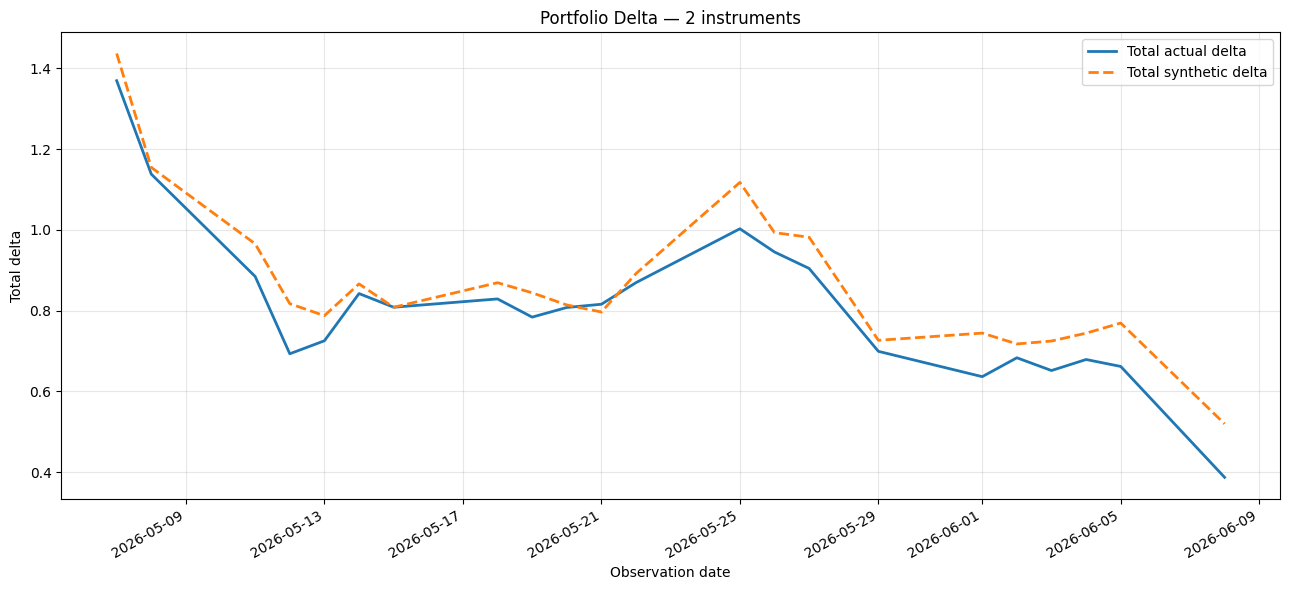

In [43]:
selected = analyzer_multi["instrument_dropdown"].value

portfolio_delta, instrument_contributions = plot_portfolio_greek(
    df_with_greeks=df_with_greeks,
    selected_instruments=selected,
    as_of_date=analyzer_multi["date_dropdown"].value,
    greek="delta",
    expiry_col="expiry",
    date_col="date",
)

In [44]:
def portfolio_greek_analyzer(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
    max_instruments=10,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import ipywidgets as widgets

    from IPython.display import display, clear_output

    # --------------------------------------------------
    # Prepare data and available instruments
    # --------------------------------------------------
    data = prepare_greek_history(
        df_with_greeks,
        expiry_col=expiry_col,
        date_col=date_col,
    )

    greeks = get_available_greeks(data)
    instrument_options = build_instrument_options(data)
    # instrument_options = build_instrument_options(df_with_greeks)


    if not instrument_options:
        raise ValueError("No instruments available.")

    dates = sorted(data["_date"].dropna().unique())

    original_date_by_parsed_date = (
        data.drop_duplicates("_date")
        .set_index("_date")[date_col]
        .to_dict()
    )

    synthetic_cache = {}

    def get_synthetic(date):
        date = pd.Timestamp(date)

        if date not in synthetic_cache:
            original_date = original_date_by_parsed_date.get(
                date, date
            )
            synthetic_cache[date] = generate_synthetic_greeks(
                df_with_greeks,
                dt=original_date,
            )

        return synthetic_cache[date]

    # --------------------------------------------------
    # Main controls
    # --------------------------------------------------
    instrument_dd = widgets.SelectMultiple(
        options=instrument_options,
        value=(),
        description="Instruments:",
        rows=min(10, max(5, len(instrument_options))),
        layout=widgets.Layout(width="650px"),
        style={"description_width": "100px"},
    )

    date_dd = widgets.Dropdown(
        options=[
            (pd.Timestamp(d).strftime("%Y-%m-%d"), pd.Timestamp(d))
            for d in dates
        ],
        value=pd.Timestamp(dates[-1]),
        description="As-of date:",
        layout=widgets.Layout(width="280px"),
    )

    greek_dd = widgets.Dropdown(
        options=greeks,
        value="delta" if "delta" in greeks else greeks[0],
        description="Greek:",
        layout=widgets.Layout(width="220px"),
    )

    view_dd = widgets.Dropdown(
        options=[
            ("Portfolio total", "portfolio"),
            ("Instrument contributions", "contributions"),
        ],
        value="portfolio",
        description="View:",
        layout=widgets.Layout(width="300px"),
    )

    position_box = widgets.VBox()
    output = widgets.Output()

    # Store Long/Short and quantity widgets by instrument tuple.
    position_widgets = {}

    # --------------------------------------------------
    # Position builder
    # --------------------------------------------------
    def rebuild_position_rows(change=None):
        selected = list(instrument_dd.value)

        if len(selected) > max_instruments:
            selected = selected[:max_instruments]
            instrument_dd.value = tuple(selected)
            return

        # Keep previous settings when possible.
        previous = position_widgets.copy()
        position_widgets.clear()
        rows = []

        if not selected:
            position_box.children = (
                widgets.HTML(
                    "<i>Select instruments above to build your portfolio.</i>"
                ),
            )
            refresh_plot()
            return

        header = widgets.HBox([
            widgets.Label(
                "Instrument",
                layout=widgets.Layout(width="390px"),
            ),
            widgets.Label(
                "Direction",
                layout=widgets.Layout(width="130px"),
            ),
            widgets.Label(
                "Quantity",
                layout=widgets.Layout(width="120px"),
            ),
        ])
        rows.append(header)

        for instrument in selected:
            option, strike, expiry = instrument

            label = widgets.Label(
                f"{option} | K={strike:g} | "
                f"Exp={pd.Timestamp(expiry):%Y-%m-%d}",
                layout=widgets.Layout(width="390px"),
            )

            old = previous.get(instrument)

            direction = widgets.Dropdown(
                options=[
                    ("Long (+)", 1),
                    ("Short (-)", -1),
                ],
                value=old["direction"].value if old else 1,
                layout=widgets.Layout(width="130px"),
                description="",
            )

            quantity = widgets.BoundedIntText(
                value=old["quantity"].value if old else 1,
                min=1,
                max=1_000_000,
                layout=widgets.Layout(width="120px"),
                description="",
            )

            position_widgets[instrument] = {
                "direction": direction,
                "quantity": quantity,
            }

            direction.observe(refresh_plot, names="value")
            quantity.observe(refresh_plot, names="value")

            rows.append(widgets.HBox([
                label,
                direction,
                quantity,
            ]))

        position_box.children = tuple(rows)
        refresh_plot()

    # --------------------------------------------------
    # Build actual and synthetic instrument contributions
    # --------------------------------------------------
    def calculate_contributions(
        selected,
        positions,
        as_of_date,
        greek,
    ):
        records = []
        as_of_date = pd.Timestamp(as_of_date)

        for instrument in selected:
            option, strike, expiry = instrument
            expiry = pd.Timestamp(expiry)

            position = positions[instrument]
            signed_quantity = (
                position["direction"] * position["quantity"]
            )

            hist = data[
                (data["_option"] == option)
                & np.isclose(data["_strike"], float(strike))
                & (data["_expiry"] == expiry)
                & (data["_date"] <= as_of_date)
            ].copy()

            if hist.empty or greek not in hist.columns:
                continue

            hist[greek] = pd.to_numeric(
                hist[greek], errors="coerce"
            )

            hist = hist.dropna(
                subset=[greek, "_days_to_exp"]
            )

            # Last available observation per date.
            hist = (
                hist.sort_index()
                .groupby("_date", as_index=False)
                .tail(1)
                .sort_values("_date")
            )

            for _, row in hist.iterrows():
                date = pd.Timestamp(row["_date"])
                actual = float(row[greek])
                synthetic_value = np.nan

                if row["_days_to_exp"] > 0:
                    synthetic = get_synthetic(date)

                    synthetic_value = select_synthetic_greek(
                        synthetic=synthetic,
                        option=option,
                        strike=float(strike),
                        target_days_to_exp=float(row["_days_to_exp"]),
                        target_rate=row["_r"],
                        greek=greek,
                    )

                records.append({
                    "date": date,
                    "instrument": instrument,
                    "label": (
                        f"{option} K={strike:g} "
                        f"Exp={expiry:%Y-%m-%d}"
                    ),
                    "direction": position["direction"],
                    "quantity": position["quantity"],
                    "signed_quantity": signed_quantity,
                    "actual": actual,
                    "synthetic": synthetic_value,
                    "actual_contribution": (
                        signed_quantity * actual
                    ),
                    "synthetic_contribution": (
                        signed_quantity * synthetic_value
                        if np.isfinite(synthetic_value)
                        else np.nan
                    ),
                })

        return pd.DataFrame(records)

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------
    def refresh_plot(change=None):
        with output:
            clear_output(wait=True)

            selected = list(instrument_dd.value)

            if not selected:
                print("Select at least one instrument.")
                return

            positions = {
                instrument: {
                    "direction": position_widgets[instrument][
                        "direction"
                    ].value,
                    "quantity": position_widgets[instrument][
                        "quantity"
                    ].value,
                }
                for instrument in selected
                if instrument in position_widgets
            }

            if len(positions) != len(selected):
                return

            greek = greek_dd.value

            contributions = calculate_contributions(
                selected=selected,
                positions=positions,
                as_of_date=date_dd.value,
                greek=greek,
            )

            if contributions.empty:
                print("No valid historical observations found.")
                return

            # Aggregate only when all selected positions have valid
            # observations on that date; don't silently show partial totals.
            portfolio = (
                contributions.groupby("date")
                .agg(
                    actual=("actual_contribution", "sum"),
                    synthetic=("synthetic_contribution", "sum"),
                    actual_count=("actual_contribution", "count"),
                    synthetic_count=("synthetic_contribution", "count"),
                )
                .sort_index()
            )

            n_selected = len(selected)

            portfolio.loc[
                portfolio["actual_count"] < n_selected, "actual"
            ] = np.nan

            portfolio.loc[
                portfolio["synthetic_count"] < n_selected, "synthetic"
            ] = np.nan

            if view_dd.value == "portfolio":
                fig, ax = plt.subplots(figsize=(13, 6))

                ax.plot(
                    portfolio.index,
                    portfolio["actual"],
                    label=f"Portfolio actual {greek}",
                    linewidth=2,
                )

                ax.plot(
                    portfolio.index,
                    portfolio["synthetic"],
                    label=f"Portfolio synthetic {greek}",
                    linewidth=2,
                    linestyle="--",
                )

                ax.set_title(
                    f"Portfolio {greek.capitalize()} | "
                    f"{len(selected)} instruments"
                )
                ax.set_ylabel(f"Net {greek}")
                ax.set_xlabel("Observation date")
                ax.grid(True, alpha=0.3)
                ax.legend()
                fig.autofmt_xdate()
                plt.tight_layout()
                plt.show()

            else:
                fig, ax = plt.subplots(figsize=(14, 7))

                for _, group in contributions.groupby("instrument"):
                    group = group.sort_values("date")
                    label = group["label"].iloc[0]
                    direction = group["direction"].iloc[0]
                    quantity = group["quantity"].iloc[0]
                    sign_label = "Long" if direction > 0 else "Short"

                    line, = ax.plot(
                        group["date"],
                        group["actual_contribution"],
                        label=(
                            f"{label} {sign_label} {quantity} "
                            "Actual"
                        ),
                    )

                    ax.plot(
                        group["date"],
                        group["synthetic_contribution"],
                        color=line.get_color(),
                        linestyle="--",
                        label=(
                            f"{label} {sign_label} {quantity} "
                            "Synthetic"
                        ),
                    )

                ax.set_title(
                    f"Signed Instrument Contributions — "
                    f"{greek.capitalize()}"
                )
                ax.set_ylabel(f"Contribution to {greek}")
                ax.set_xlabel("Observation date")
                ax.grid(True, alpha=0.3)
                ax.legend(fontsize=8, loc="best")
                fig.autofmt_xdate()
                plt.tight_layout()
                plt.show()

            print(f"Selected instruments: {len(selected)}")
            print(f"Greek: {greek}")
            print(f"As-of date: {pd.Timestamp(date_dd.value):%Y-%m-%d}")

            display(portfolio.tail(10))

    # --------------------------------------------------
    # Wire up controls
    # --------------------------------------------------
    instrument_dd.observe(rebuild_position_rows, names="value")
    date_dd.observe(refresh_plot, names="value")
    greek_dd.observe(refresh_plot, names="value")
    view_dd.observe(refresh_plot, names="value")

    controls = widgets.VBox([
        widgets.HBox([date_dd, greek_dd, view_dd]),
        instrument_dd,
        widgets.HTML("<b>Portfolio positions</b>"),
        position_box,
    ])

    display(controls, output)

    return {
        "data": data,
        "instrument_dropdown": instrument_dd,
        "date_dropdown": date_dd,
        "greek_dropdown": greek_dd,
        "view_dropdown": view_dd,
        "position_widgets": position_widgets,
        "output": output,
        "synthetic_cache": synthetic_cache,
    }

In [45]:
def plot_portfolio_payoff(
    analyzer,
    spot_min=None,
    spot_max=None,
    n_points=500,
    lot_size=1,
    premium_col=None,
):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    selected = list(analyzer["instrument_dropdown"].value)
    position_widgets = analyzer["position_widgets"]

    if not selected:
        raise ValueError("Select at least one instrument first.")

    # Extract strike range
    strikes = [float(instrument[1]) for instrument in selected]
    min_strike = min(strikes)
    max_strike = max(strikes)

    # Default underlying price range around selected strikes
    if spot_min is None:
        spot_min = min_strike * 0.8
    if spot_max is None:
        spot_max = max_strike * 1.2

    spots = np.linspace(spot_min, spot_max, n_points)
    total_payoff = np.zeros_like(spots, dtype=float)

    fig, ax = plt.subplots(figsize=(12, 6))

    for instrument in selected:
        option, strike, expiry = instrument
        strike = float(strike)

        direction = position_widgets[instrument]["direction"].value
        quantity = position_widgets[instrument]["quantity"].value

        signed_quantity = direction * quantity * lot_size

        if option.upper() in ("CE", "CALL", "C"):
            payoff_per_unit = np.maximum(spots - strike, 0.0)
        elif option.upper() in ("PE", "PUT", "P"):
            payoff_per_unit = np.maximum(strike - spots, 0.0)
        else:
            print(f"Skipping unrecognised option type: {option}")
            continue

        position_payoff = signed_quantity * payoff_per_unit
        total_payoff += position_payoff

        ax.plot(
            spots,
            position_payoff,
            linewidth=1,
            alpha=0.5,
            label=f"{option} K={strike:g} "
                  f"{'Long' if direction > 0 else 'Short'} {quantity}",
        )

    ax.plot(
        spots,
        total_payoff,
        color="black",
        linewidth=2.5,
        label="Net portfolio payoff",
    )

    ax.axhline(0, linewidth=1, linestyle="--")
    ax.set_xlabel("Underlying price at expiry")
    ax.set_ylabel("Payoff")
    ax.set_title("Portfolio Option Payoff at Expiry")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({
        "underlying_price": spots,
        "portfolio_payoff": total_payoff,
    })


In [46]:
# Launch the analyzer
portfolio_analyzer = portfolio_greek_analyzer(
    df_with_greeks,
    expiry_col="expiry",
    date_col="date",
    max_instruments=10,
)

Output()

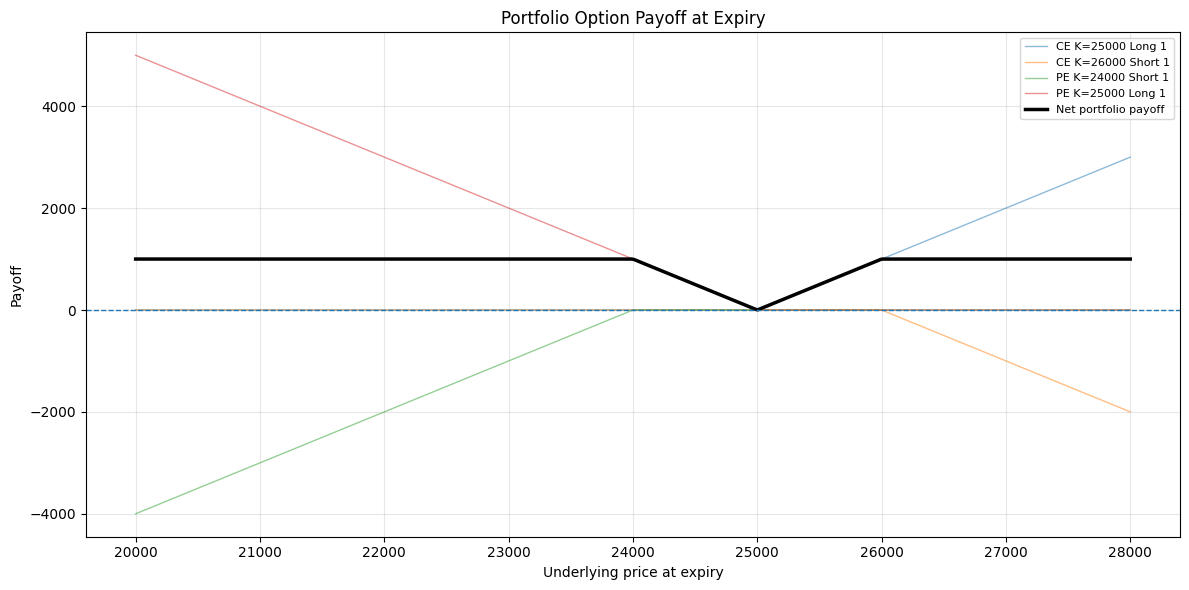

In [50]:
payoff_df = plot_portfolio_payoff(
    portfolio_analyzer,
    spot_min=20000,
    spot_max=28000,
)

In [ ]:
condition = (
    (df_with_greeks['expiry'] =='2025-08-07') &
    (df_with_greeks['option_type'] =='CE') &
    (df_with_greeks['strike'] ==23200) 
) 
nifty_df[condition]

,index,date,timestamp,expiry,strike,option_type,close,date_dt,exdate_dt,time_to_expiry,days_to_exp,ttm,spot,moneyness,mid_price,r,iv
178785,223368,2025-07-21,2025-07-21,2025-08-07,23200.0,CE,2356.50,2025-07-21,2025-08-07,17 days,17,0.046575,25090.70,0.924645,2356.50,0.064696,0.567062
179901,224647,2025-07-22,2025-07-22,2025-08-07,23200.0,CE,2356.50,2025-07-22,2025-08-07,16 days,16,0.043836,25060.90,0.925745,2356.50,0.071433,0.598141
181487,226879,2025-07-23,2025-07-23,2025-08-07,23200.0,CE,2356.50,2025-07-23,2025-08-07,15 days,15,0.041096,25219.90,0.919908,2356.50,0.058852,0.537991
182404,227664,2025-07-24,2025-07-24,2025-08-07,23200.0,CE,2356.50,2025-07-24,2025-08-07,14 days,14,0.038356,25062.10,0.925701,2356.50,0.073515,0.638860
183457,229046,2025-07-25,2025-07-25,2025-08-07,23200.0,CE,2356.50,2025-07-25,2025-08-07,13 days,13,0.035616,24837.00,0.934090,2356.50,0.063462,0.767987
185001,231249,2025-07-28,2025-07-28,2025-08-07,23200.0,CE,1531.60,2025-07-28,2025-08-07,10 days,10,0.027397,24680.90,0.939998,1531.60,0.098354,0.285869
188689,236154,2025-07-31,2025-07-31,2025-08-07,23200.0,CE,1607.65,2025-07-31,2025-08-07,7 days,7,0.019178,24768.35,0.936679,1607.65,NaN,0.333814
189519,237001,2025-08-01,2025-08-01,2025-08-07,23200.0,CE,1607.65,2025-08-01,2025-08-07,6 days,6,0.016438,24565.35,0.944420,1607.65,0.071299,0.598641
191032,239197,2025-08-04,2025-08-04,2025-08-07,23200.0,CE,1524.70,2025-08-04,2025-08-07,3 days,3,0.008219,24722.75,0.938407,1524.70,0.054131,0.296591
193224,241676,2025-08-06,2025-08-06,2025-08-07,23200.0,CE,1433.25,2025-08-06,2025-08-07,1 days,1,0.002740,24574.20,0.944080,1433.25,0.067047,0.894455
